# Rossmann - Machine Learning

### This notebook is about training models for price prediction

**1. Loading and preparing the data**

In [5]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
# Load cleaned datasets with consistent data types
PROCESSED_PATH = Path("../data/processed")

train_df = pd.read_csv(
    PROCESSED_PATH / "train_merged.csv",
    dtype={"state_holiday": "string"}
)

test_df = pd.read_csv(
    PROCESSED_PATH / "test_merged.csv",
    dtype={"state_holiday": "string"}
)

# Validate categorical values
print(test_df["state_holiday"].value_counts(dropna=False))
print(test_df["state_holiday"].dtype)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

state_holiday
0    40908
a      180
Name: count, dtype: Int64
string
Train shape: (1017209, 18)
Test shape: (41088, 17)


**2. Check for anomalies**

In [7]:
from IPython.display import display, Markdown

# Train dataset
display(Markdown("### TRAIN DATASET"))
display(pd.DataFrame({
    "Data Type": train_df.dtypes,
    "Non-Null Count": train_df.count(),
    "Null Count": train_df.isna().sum()
}))

# Test dataset
display(Markdown("### TEST DATASET"))
display(pd.DataFrame({
    "Data Type": test_df.dtypes,
    "Non-Null Count": test_df.count(),
    "Null Count": test_df.isna().sum()
}))

### TRAIN DATASET

,Data Type,Non-Null Count,Null Count
store,int64,1017209,0
day_of_week,int64,1017209,0
date,object,1017209,0
sales,int64,1017209,0
customers,int64,1017209,0
open,int64,1017209,0
promo,int64,1017209,0
state_holiday,string[python],1017209,0
school_holiday,int64,1017209,0
store_type,object,1017209,0


### TEST DATASET

,Data Type,Non-Null Count,Null Count
id,int64,41088,0
store,int64,41088,0
day_of_week,int64,41088,0
date,object,41088,0
open,int64,41088,0
promo,int64,41088,0
state_holiday,string[python],41088,0
school_holiday,int64,41088,0
store_type,object,41088,0
assortment,object,41088,0


In [8]:
# Convert date to datetime
train_df["date"] = pd.to_datetime(train_df["date"])
test_df["date"] = pd.to_datetime(test_df["date"])

In [9]:
# Check missing values by Promo2 status
promo_cols = [
    "promo2_since_week",
    "promo2_since_year",
    "promo_interval"
]

for name, df in [("TRAIN", train_df), ("TEST", test_df)]:
    print(f"\n{name} DATASET")

    display(
        df.groupby("promo2")[promo_cols]
        .agg(lambda x: x.isna().mean() * 100)
        .round(2)
    )


TRAIN DATASET


,promo2_since_week,promo2_since_year,promo_interval
promo2,,,
0,100.0,100.0,100.0
1,0.0,0.0,0.0



TEST DATASET


,promo2_since_week,promo2_since_year,promo_interval
promo2,,,
0,100.0,100.0,100.0
1,0.0,0.0,0.0


Obs:

**2. Quick EDA**

count    844392.000000
mean       6955.514291
std        3104.214680
min           0.000000
25%        4859.000000
50%        6369.000000
75%        8360.000000
max       41551.000000
Name: sales, dtype: float64

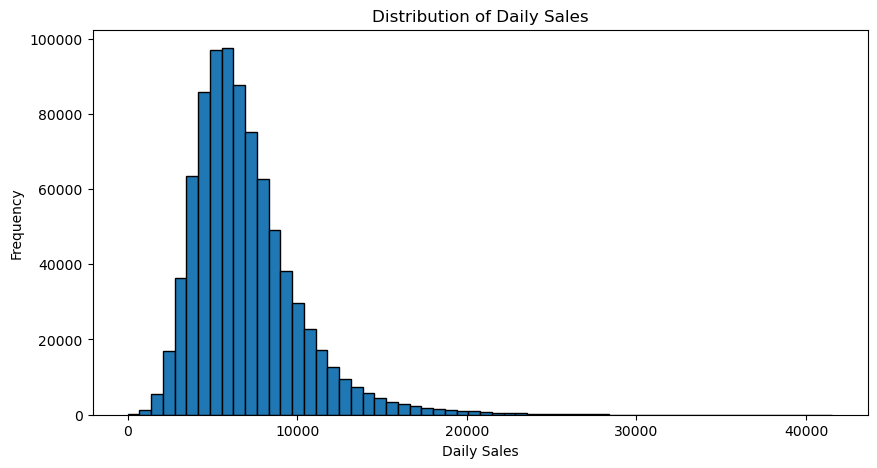

In [10]:

# Prepare data for exploratory analysis
train_open_df = train_df[train_df["open"] == 1].copy()

# Check target statistics
display(train_open_df["sales"].describe())


plt.figure(figsize=(10, 5))
plt.hist(train_open_df["sales"], bins=60, edgecolor="black")

plt.title("Distribution of Daily Sales")
plt.xlabel("Daily Sales")
plt.ylabel("Frequency")
plt.show()

Observation: There are no negative sales values. The distribution of daily sales is right-skewed, with most store-day observations recording sales below €10,000. The mean (€6,955.51) is higher than the median (€6,369), suggesting that higher sales values influence the average. The distribution also shows a long right tail, indicating potential outlier


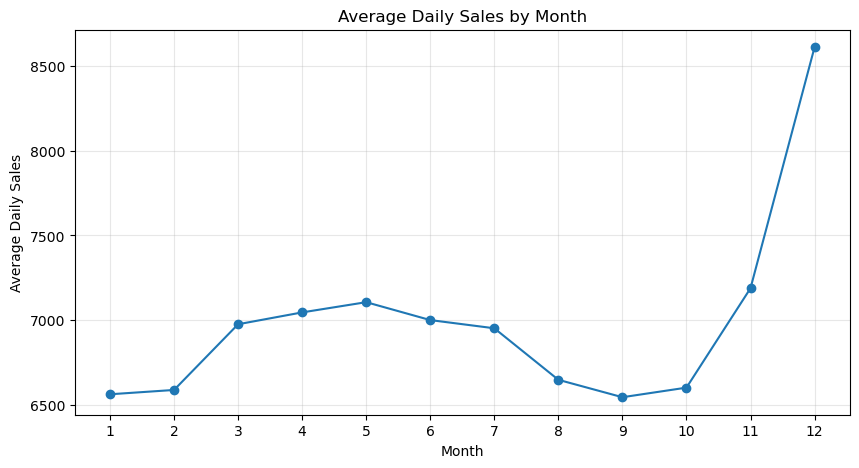

In [11]:
# Average daily sales by month
monthly_sales = (
    train_open_df.groupby(train_open_df["date"].dt.month)["sales"]
    .mean()
)

plt.figure(figsize=(10, 5))
monthly_sales.plot(kind="line", marker="o")

plt.title("Average Daily Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.show()

**Observation:** Average daily sales show a seasonal pattern, with a particularly strong increase in December, potentially associated with Christmas shopping. Sales are relatively stable during spring, while August and September show lower average values.

These findings suggest that seasonality may influence sales performance, making calendar-based features potentially useful for the forecasting model.

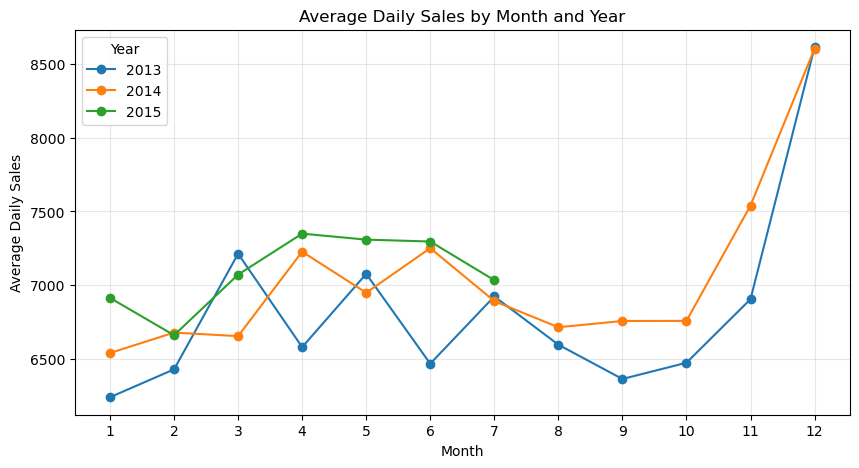

In [12]:
# Average daily sales by year and month
monthly_by_year = (
    train_open_df
    .groupby([
        train_open_df["date"].dt.year,
        train_open_df["date"].dt.month
    ])["sales"]
    .mean()
    .unstack(level=0)
)

monthly_by_year.plot(
    figsize=(10, 5),
    marker="o"
)

plt.title("Average Daily Sales by Month and Year")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.show()

**Observation:** Average daily sales exhibit seasonal patterns, with December consistently recording the highest sales in both 2013 and 2014, potentially reflecting increased demand during the Christmas period.

Sales also increase in November, particularly in 2014, while the remaining months show variations across years.

As the 2015 dataset only covers January to July, a complete year-over-year comparison is not possible.

These findings suggest that calendar-based features, particularly month and holiday indicators, may be useful for sales forecasting.

,count,mean,median
promo,,,
0,467496,5929.41,5459.0
1,376896,8228.28,7649.0


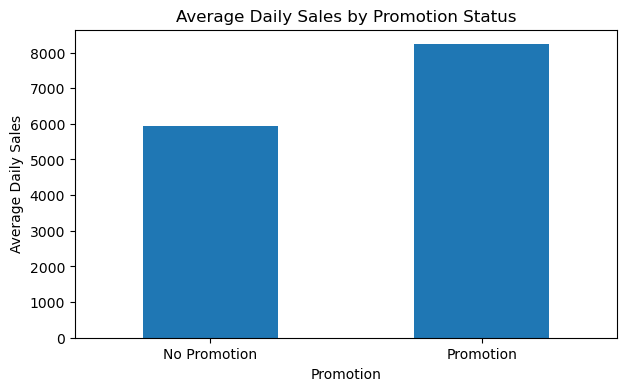

In [13]:
# Compare sales with and without promotions
promo_sales = (
    train_open_df.groupby("promo")["sales"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(promo_sales)

promo_sales["mean"].plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Average Daily Sales by Promotion Status")
plt.xlabel("Promotion")
plt.ylabel("Average Daily Sales")
plt.xticks([0, 1], ["No Promotion", "Promotion"], rotation=0)
plt.show()

**Observation:** Stores recorded higher average daily sales on promotional days (€8,228.28) compared to non-promotional days (€5,929.41), representing an increase of approximately 38.8%.

Median sales were also higher during promotional periods, suggesting a consistent positive association between promotions and sales performance.

However, this relationship does not necessarily imply causation, as other factors such as seasonality, store characteristics, and customer demand may also influence sales.

In [14]:
# Calculate IQR
Q1 = train_open_df["sales"].quantile(0.25)
Q3 = train_open_df["sales"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = train_open_df[
    (train_open_df["sales"] < lower_bound) |
    (train_open_df["sales"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outliers:", len(outliers))
print("Percentage:", round(len(outliers) / len(train_open_df) * 100, 2), "%")

Q1: 4859.0
Q3: 8360.0
IQR: 3501.0
Lower bound: -392.5
Upper bound: 13611.5
Potential outliers: 30769
Percentage: 3.64 %


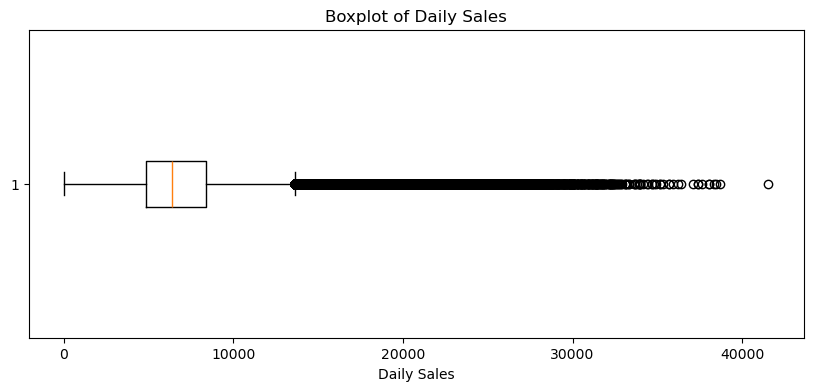

In [15]:
plt.figure(figsize=(10, 4))
plt.boxplot(train_open_df["sales"], vert=False)

plt.title("Boxplot of Daily Sales")
plt.xlabel("Daily Sales")
plt.show()

**Observation:** The IQR method identified 30,769 potential outliers, representing 3.64% of observations on days when stores were open. These observations are concentrated in the upper tail of the sales distribution, with values exceeding €13,611.50.

However, these values do not necessarily represent errors. Differences in store characteristics, promotional activities, and seasonal demand may explain unusually high sales.

Therefore, potential outliers will be retained at this stage to preserve meaningful business information. Their impact on model performance can be assessed during model evaluation.

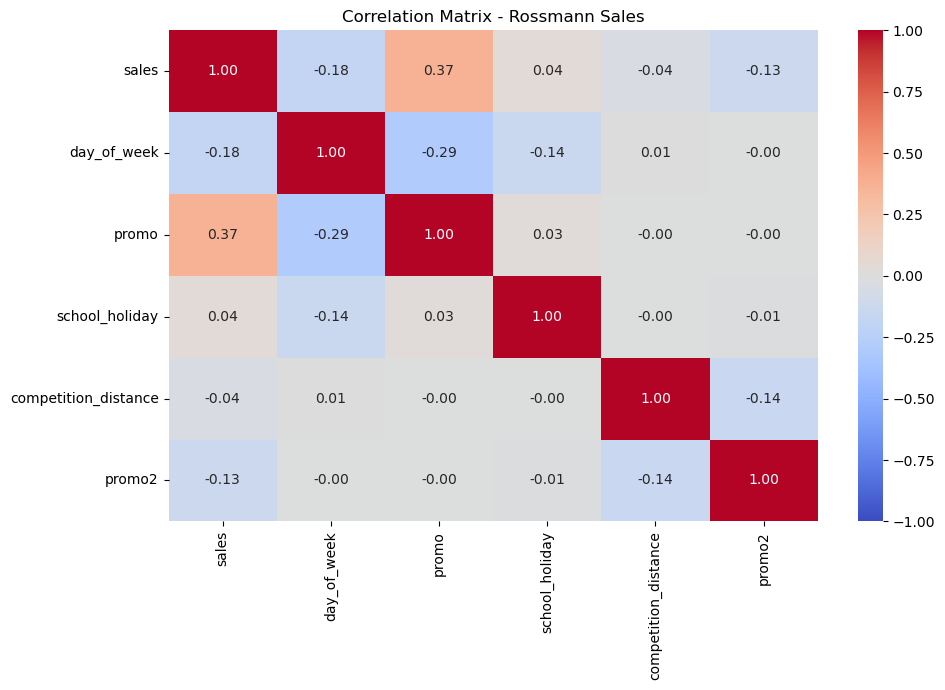

In [16]:
# Select numerical and binary features
corr_features = [
    "sales",
    "day_of_week",
    "promo",
    "school_holiday",
    "competition_distance",
    "promo2"
]

# Calculate Pearson correlation
corr_matrix = train_open_df[corr_features].corr()

# Plot correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix - Rossmann Sales")
plt.tight_layout()
plt.show()

In [17]:
# Correlation with target variable
sales_correlation = (
    corr_matrix["sales"]
    .drop("sales")
    .sort_values(ascending=False)
)

display(
    sales_correlation.to_frame(
        name="Correlation with Sales"
    )
)

,Correlation with Sales
promo,0.368145
school_holiday,0.038617
competition_distance,-0.036396
promo2,-0.127596
day_of_week,-0.178736


In [18]:
# Prepare data for correlation analysis
corr_df = train_df.copy()

# Extract date features
corr_df["month"] = corr_df["date"].dt.month
corr_df["year"] = corr_df["date"].dt.year
corr_df["day_of_month"] = corr_df["date"].dt.day

# Exclude target leakage, identifiers and original date
corr_df = corr_df.drop(
    columns=["customers", "store", "date"]
)

# Encode categorical variables for EDA
categorical_cols = corr_df.select_dtypes(
    include=["object", "string", "category"]
).columns

corr_df = pd.get_dummies(
    corr_df,
    columns=categorical_cols,
    dummy_na=True,
    dtype=int
)

# Calculate correlation matrix
corr_matrix = corr_df.corr(numeric_only=True)

# Correlation with Sales
sales_corr = (
    corr_matrix["sales"]
    .drop("sales")
    .sort_values(key=abs, ascending=False)
)

display(sales_corr.to_frame("Correlation with Sales"))

,Correlation with Sales
open,0.678472
day_of_week,-0.462125
promo,0.452345
state_holiday_0,0.254216
state_holiday_a,-0.203028
store_type_b,0.139940
state_holiday_b,-0.117497
state_holiday_c,-0.092618
promo2,-0.091040
promo_interval_nan,0.091040


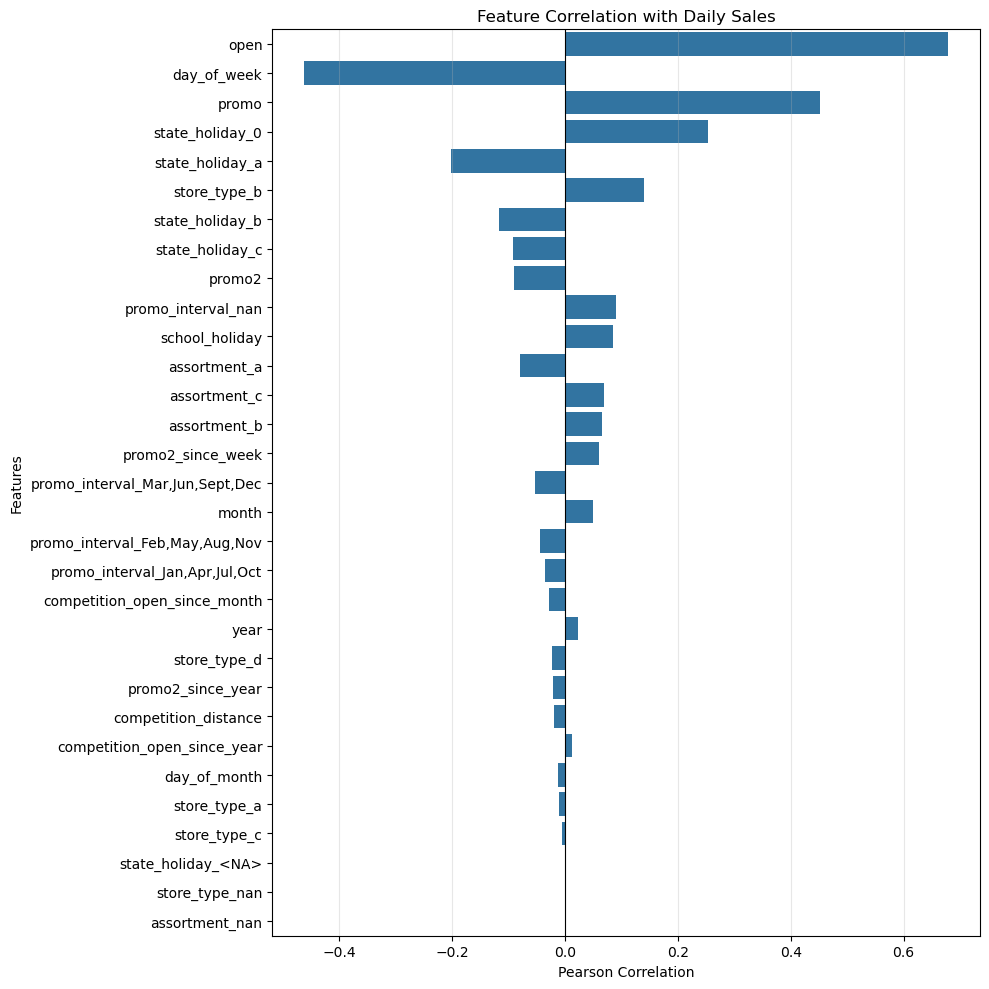

In [19]:
plt.figure(figsize=(10, 10))

sns.barplot(
    x=sales_corr.values,
    y=sales_corr.index
)

plt.title("Feature Correlation with Daily Sales")
plt.xlabel("Pearson Correlation")
plt.ylabel("Features")

plt.axvline(0, color="black", linewidth=0.8)
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

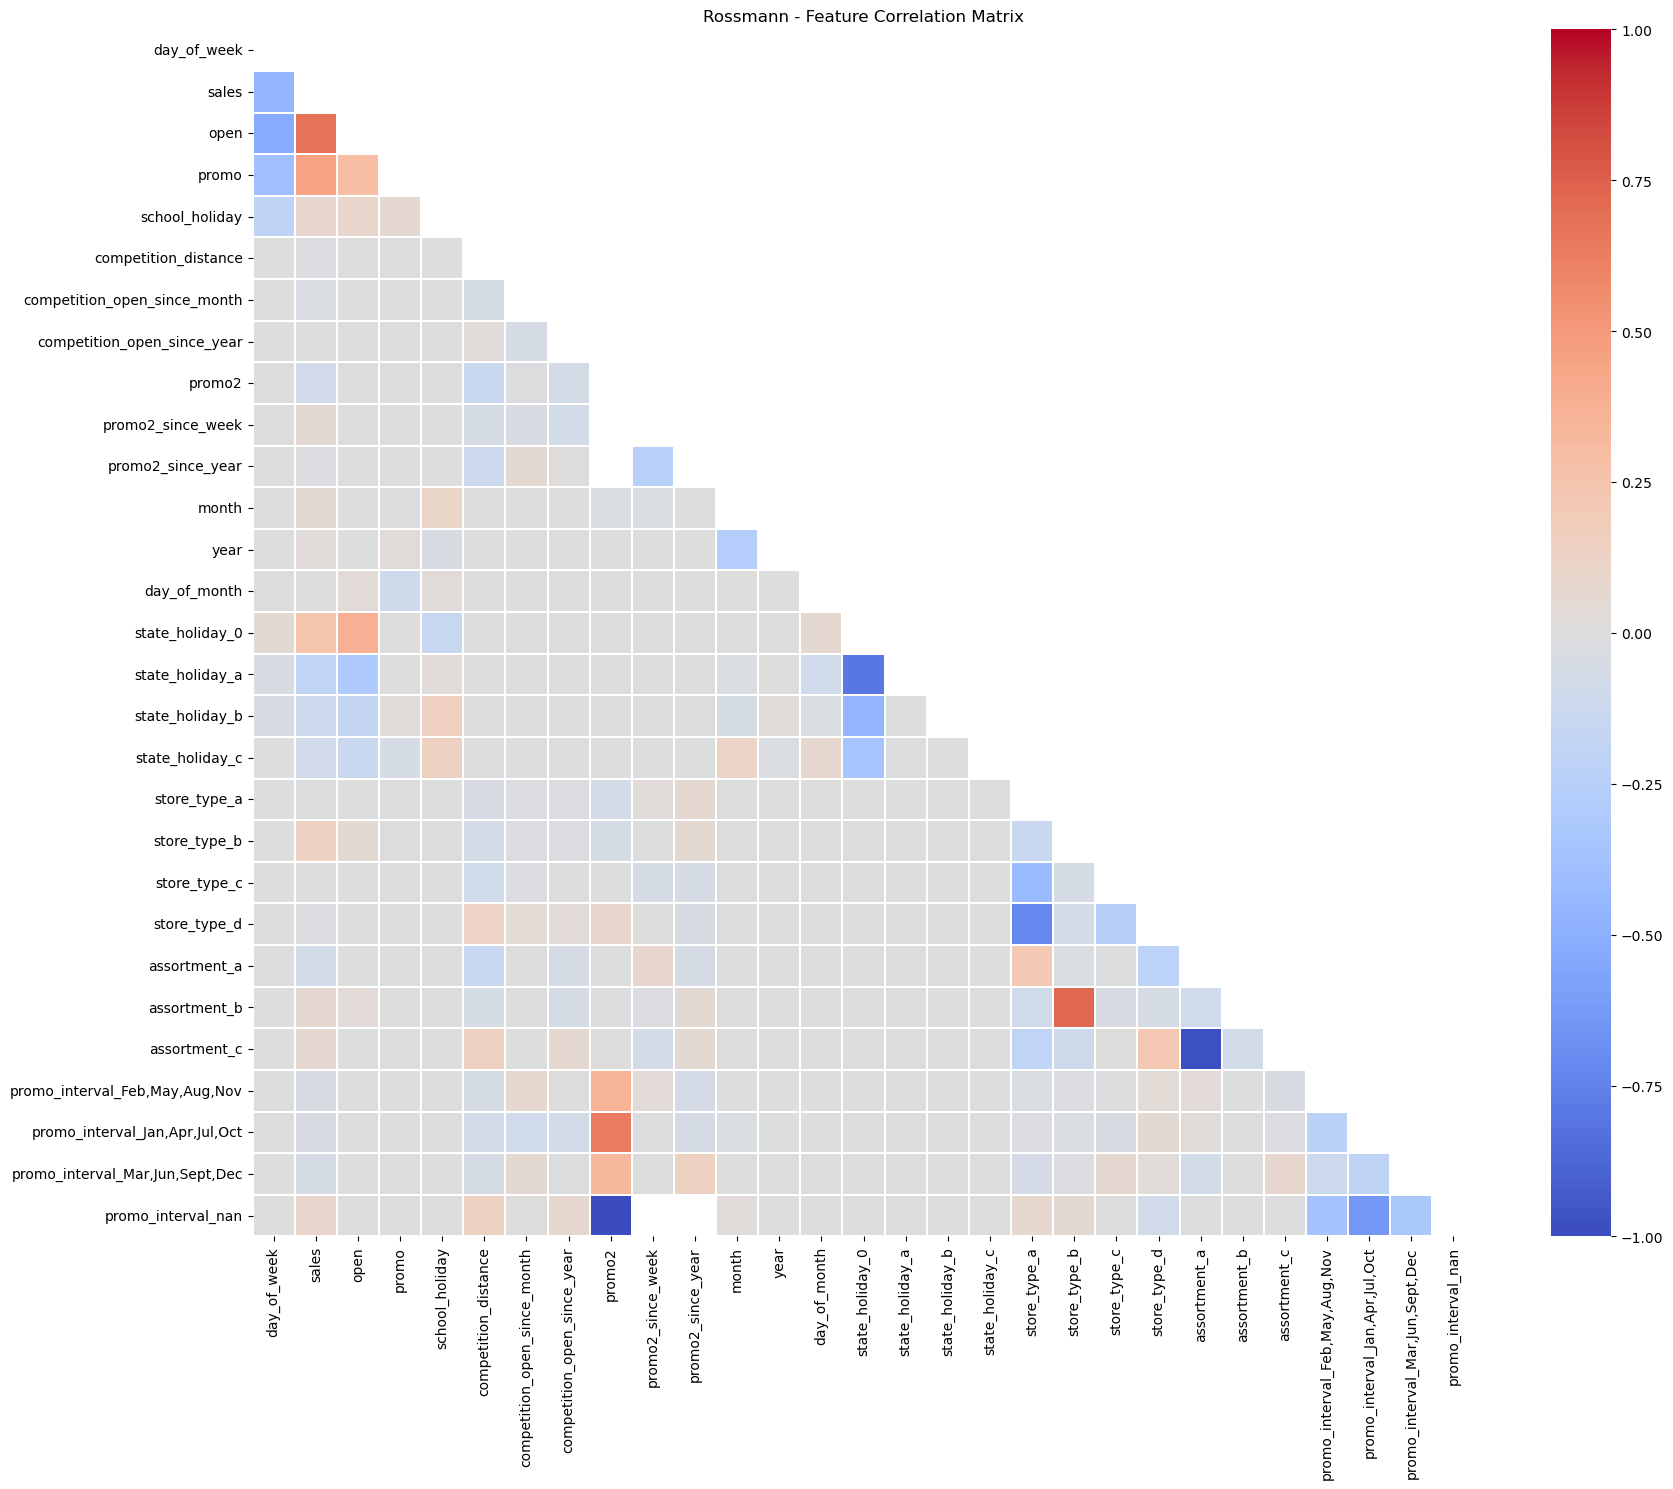

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Remove constant columns
valid_cols = corr_df.columns[
    corr_df.nunique(dropna=True) > 1
]

# Calculate correlation matrix
corr_matrix = corr_df[valid_cols].corr(numeric_only=True)

# Hide upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(18, 15))

sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3
)

plt.title("Rossmann - Feature Correlation Matrix")
plt.tight_layout()
plt.show()

**Observation:** The correlation matrix highlights several relationships between store characteristics, operational factors, and daily sales.

Store opening status, promotions, and day of the week show the strongest linear associations with sales. Strong correlations were also identified between certain features, particularly `promo2` and `promo_interval_nan`, suggesting potential redundancy.

However, weak linear correlations do not necessarily indicate low predictive value. Features such as month, store type, and competition-related variables may capture non-linear patterns or interactions that Pearson correlation does not detect.

Therefore, feature selection will not rely exclusively on correlation coefficients. The predictive contribution of each feature will be evaluated during model training and validation.